# Assignment 4 — Sequential Modelling with Recurrent Networks

**Task 1:** Kannada handwritten digits, read row by row  
**Task 2:** Spoken Arabic digits using MFCC sequences



## Task 1 — Kannada handwritten digits

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

os.makedirs("results", exist_ok=True)

TensorFlow version: 2.21.0
GPU available: []


In [2]:
import os
import pandas as pd

filename = "/content/Dig-MNIST.csv (1).zip"
if not os.path.exists(filename):
    try:
        from google.colab import files
        uploaded = files.upload()
        filename = next(iter(uploaded))
    except Exception as exc:
        raise FileNotFoundError(
            "Place the labelled Dig-MNIST CSV/ZIP in the runtime and update filename."
        ) from exc

df = pd.read_csv(filename)
print("Dataset shape:", df.shape)
print(df.head())

Saving Dig-MNIST.csv.zip to Dig-MNIST.csv.zip
Dataset shape: (10240, 785)
   label  pixel0  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  \
0      0       0       0       0       0       0       0       0       0   
1      1       0       0       0       0       0       0       0       0   
2      2       0       0       0       0       0       0       0       0   
3      3       0       0       0       0       0       0       0       0   
4      4       0       0       0       0       0       0       0       0   

   pixel8  ...  pixel774  pixel775  pixel776  pixel777  pixel778  pixel779  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0         0         0         0   
3       0  ...         0         0         0         0         0         0   
4       0  ...         0         0         0         0         0         0   



In [3]:
# Extract labels
if "label" not in df.columns:
    raise ValueError(
        "The CSV must contain a 'label' column. "
        "Upload the labelled train.csv file, not test.csv."
    )

y = df["label"].to_numpy().astype("int64")

# Extract the 784 pixel columns, ignoring any optional ID column
pixel_cols = [
    col for col in df.columns
    if col != "label" and (
        str(col).lower().startswith("pixel")
        or str(col).isdigit()
    )
]

if len(pixel_cols) != 784:
    # Fallback: select all numeric columns except label and common IDs
    excluded = {"label", "id", "imageid"}
    pixel_cols = [
        col for col in df.columns
        if str(col).lower() not in excluded
        and pd.api.types.is_numeric_dtype(df[col])
    ]

    # If an ID column is present, remove it
    if len(pixel_cols) == 785:
        pixel_cols = [
            col for col in pixel_cols
            if str(col).lower() not in {"id", "imageid"}
        ]

if len(pixel_cols) != 784:
    raise ValueError(
        f"Expected 784 pixel columns but found {len(pixel_cols)}. "
        "Check the CSV format."
    )

X_images = df[pixel_cols].to_numpy(dtype="float32")
X_images = X_images.reshape(-1, 28, 28) / 255.0

# Required sequential representation:
# samples x time steps x features = N x 28 x 28
X = X_images.copy()

num_classes = len(np.unique(y))

print("Sequential input shape:", X.shape)
print("Labels shape:", y.shape)
print("Classes:", np.unique(y))
print("Number of classes:", num_classes)

assert X.shape[1:] == (28, 28)
assert num_classes == 10, "Expected all 10 digit classes."

Sequential input shape: (10240, 28, 28)
Labels shape: (10240,)
Classes: [0 1 2 3 4 5 6 7 8 9]
Number of classes: 10


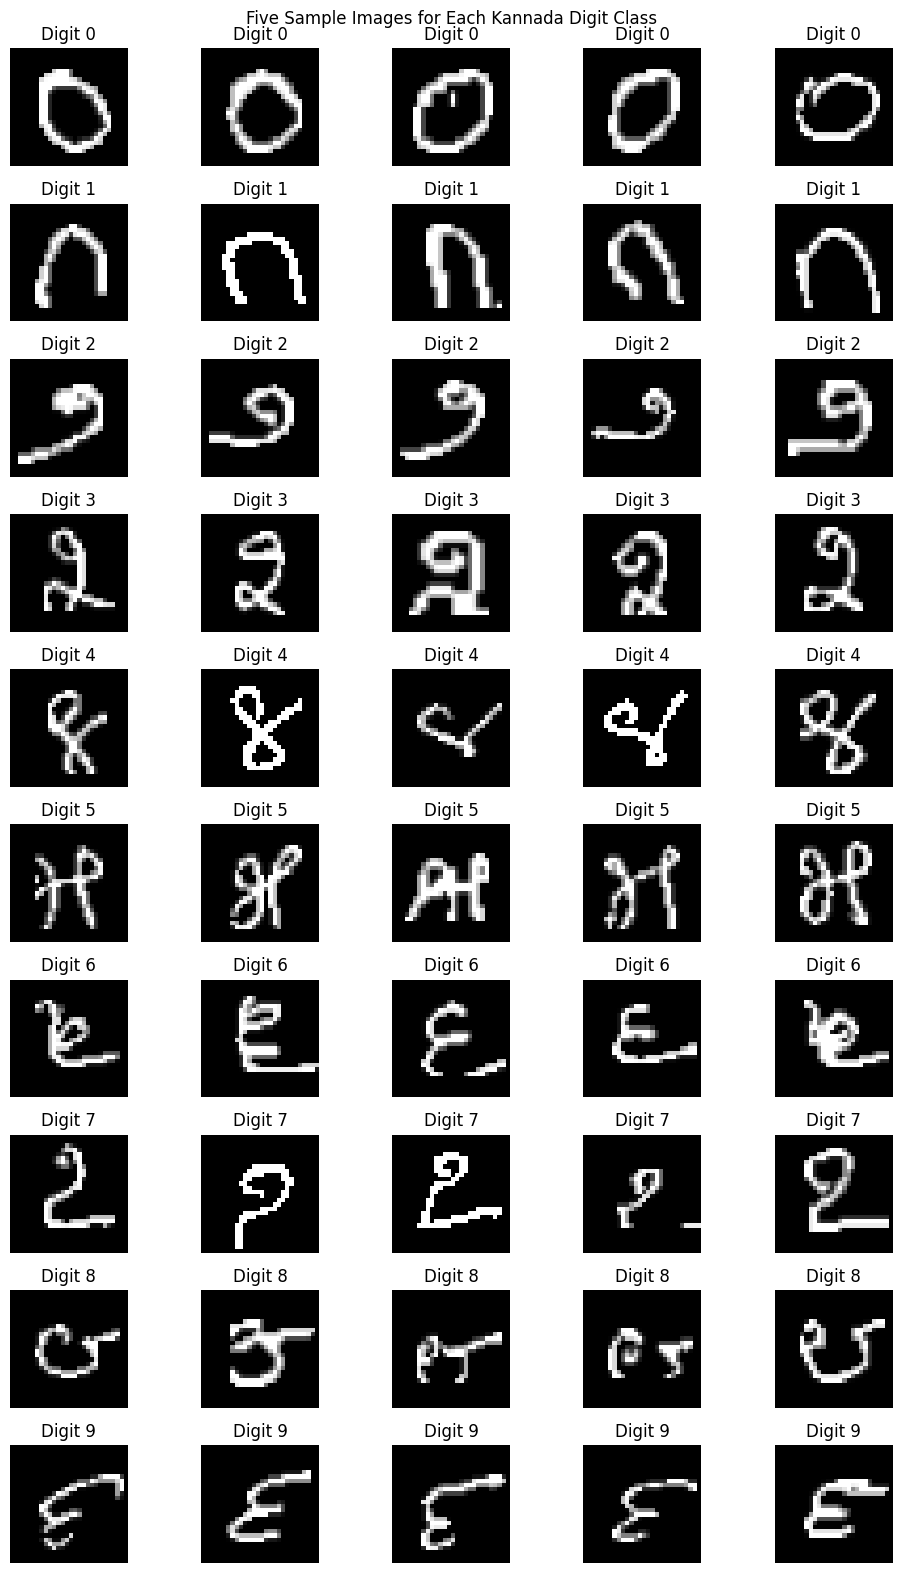

In [4]:
fig, axes = plt.subplots(10, 5, figsize=(10, 16))

for digit in range(10):
    indices = np.where(y == digit)[0][:5]

    for j in range(5):
        ax = axes[digit, j]

        if j < len(indices):
            ax.imshow(X_images[indices[j]], cmap="gray")
            ax.set_title(f"Digit {digit}")
        ax.axis("off")

# Assignment requirement: show five separate examples for every class (10 x 5 grid).\nplt.suptitle("Five Sample Images for Each Kannada Digit Class")
plt.tight_layout()
plt.savefig("results/digit_samples.png", dpi=200, bbox_inches="tight")
plt.show()

In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\nInput shapes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training samples: 7168
Validation samples: 1536
Test samples: 1536

Input shapes:
Training: (7168, 28, 28)
Validation: (1536, 28, 28)
Test: (1536, 28, 28)


In [6]:
CONFIGS = [
    {
        "name": "RNN_64_lr001",
        "model": "RNN",
        "units": 64,
        "dropout": 0.0,
        "learning_rate": 0.001
    },
    {
        "name": "RNN_128_lr001",
        "model": "RNN",
        "units": 128,
        "dropout": 0.2,
        "learning_rate": 0.001
    },
    {
        "name": "LSTM_64_lr001",
        "model": "LSTM",
        "units": 64,
        "dropout": 0.0,
        "learning_rate": 0.001
    },
    {
        "name": "LSTM_128_lr0005",
        "model": "LSTM",
        "units": 128,
        "dropout": 0.2,
        "learning_rate": 0.0005
    },
    {
        "name": "GRU_64_lr001",
        "model": "GRU",
        "units": 64,
        "dropout": 0.0,
        "learning_rate": 0.001
    },
    {
        "name": "GRU_128_lr0005",
        "model": "GRU",
        "units": 128,
        "dropout": 0.2,
        "learning_rate": 0.0005
    }
]

EPOCHS = 100  # safety cap; stopping uses the convergence rule
BATCH_SIZE = 128
CONVERGENCE_TOL = 1e-4

def build_model(config):
    model = Sequential()
    model.add(tf.keras.Input(shape=(28, 28)))

    layer_type = {
        "RNN": SimpleRNN,
        "LSTM": LSTM,
        "GRU": GRU
    }[config["model"]]

    model.add(
        layer_type(
            config["units"],
            dropout=config["dropout"]
        )
    )
    model.add(Dense(64, activation="relu"))
    model.add(Dense(10, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=config["learning_rate"]
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

print("Total configurations:", len(CONFIGS))


class TrainingLossConvergence(tf.keras.callbacks.Callback):
    def __init__(self, tolerance=1e-4):
        super().__init__()
        self.tolerance = tolerance
        self.converged = False
        self.stop_reason = "maximum epoch safety cap reached"
        self.best_val_loss = float("inf")
        self.best_weights = None

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        val_loss = logs.get("val_loss")
        if val_loss is not None and val_loss < self.best_val_loss:
            self.best_val_loss = val_loss
            self.best_weights = self.model.get_weights()
        current_loss = float(logs["loss"])
        if hasattr(self, "previous_loss"):
            loss_change = abs(current_loss - self.previous_loss)
            if loss_change < self.tolerance:
                self.converged = True
                self.stop_reason = f"converged: |Δ training loss|={loss_change:.6g} < {self.tolerance}"
                self.model.stop_training = True
        self.previous_loss = current_loss

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)

Total configurations: 6


In [7]:
histories = {}
models = {}
results = []

for config in CONFIGS:
    print("\n" + "=" * 65)
    print("Training:", config["name"])
    print("=" * 65)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_model(config)

    convergence_cb = TrainingLossConvergence(CONVERGENCE_TOL)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[convergence_cb],
        verbose=1
    )

    # Evaluate restored best-validation-loss weights
    train_loss, train_acc = model.evaluate(
        X_train, y_train, verbose=0
    )
    val_loss, val_acc = model.evaluate(
        X_val, y_val, verbose=0
    )
    test_loss, test_acc = model.evaluate(
        X_test, y_test, verbose=0
    )

    histories[config["name"]] = history.history
    models[config["name"]] = model

    results.append({
        "Configuration": config["name"],
        "Architecture": config["model"],
        "Units": config["units"],
        "Dropout": config["dropout"],
        "Learning Rate": config["learning_rate"],
        "Epochs Trained": len(history.history["loss"]),
        "Converged": convergence_cb.converged,
        "Stopping Reason": convergence_cb.stop_reason,
        "Training Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Test Accuracy": test_acc,
        "Training Loss": train_loss,
        "Test Loss": test_loss
    })

    print(f"Training accuracy:   {train_acc:.4f}")
    print(f"Validation accuracy:  {val_acc:.4f}")
    print(f"Test accuracy:       {test_acc:.4f}")

results_df = pd.DataFrame(results)
results_df.to_csv("results/hyperparameter_results.csv", index=False)

print("\nAll experiments completed.")

# Preserve Task 1 results before Task 2 reuses the results_df variable.
task1_results_df = results_df.copy()


Training: RNN_64_lr001
Epoch 1/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.4314 - loss: 1.7888 - val_accuracy: 0.6042 - val_loss: 1.2265
Epoch 2/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6844 - loss: 0.9909 - val_accuracy: 0.7142 - val_loss: 0.8705
Epoch 3/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7561 - loss: 0.7687 - val_accuracy: 0.7526 - val_loss: 0.7581
Epoch 4/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7893 - loss: 0.6742 - val_accuracy: 0.7891 - val_loss: 0.6807
Epoch 5/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8115 - loss: 0.6076 - val_accuracy: 0.8008 - val_loss: 0.6530
Epoch 6/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8290 - loss: 0.5621 - val_accuracy: 0.8079 - val_loss: 0.6362
Epoch 7/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8436 - loss: 0.5188 - val_accuracy: 0.8112 - val_loss: 0.6176
Epoch 8/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8514 - loss: 0

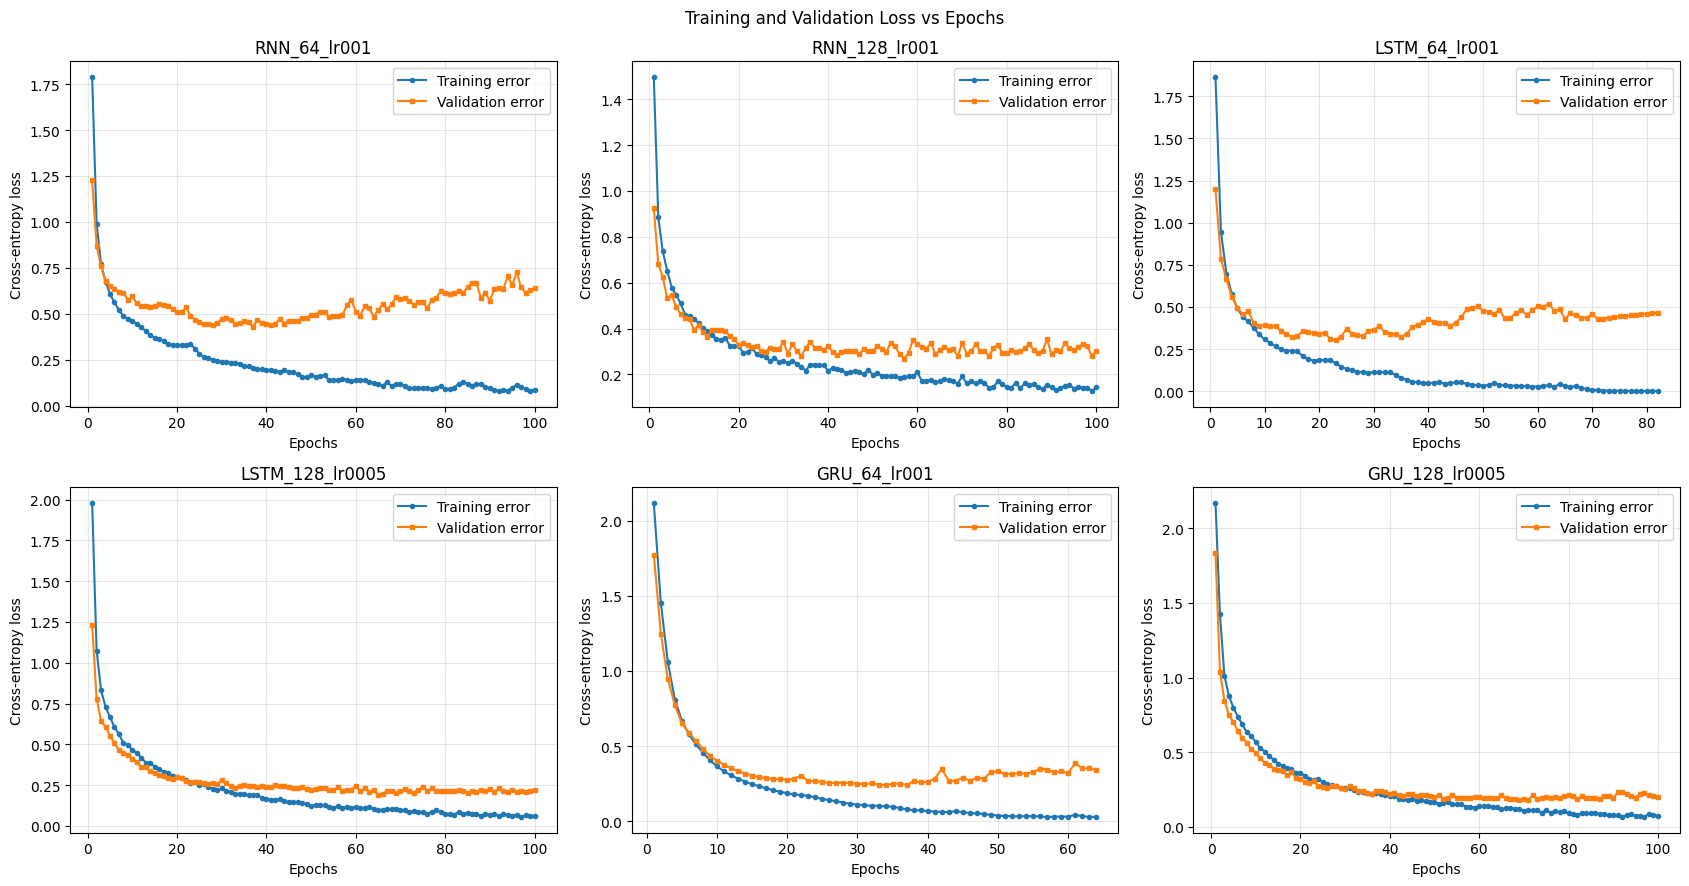

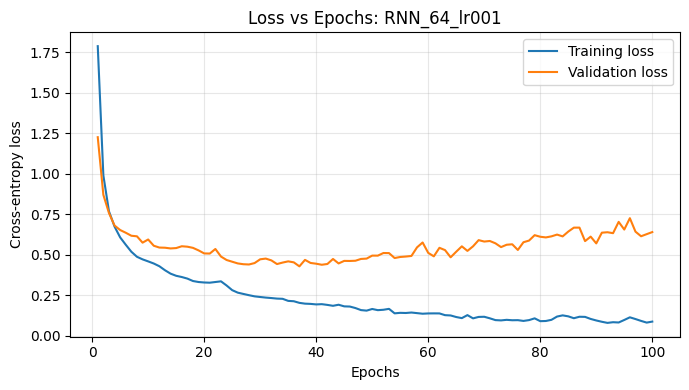

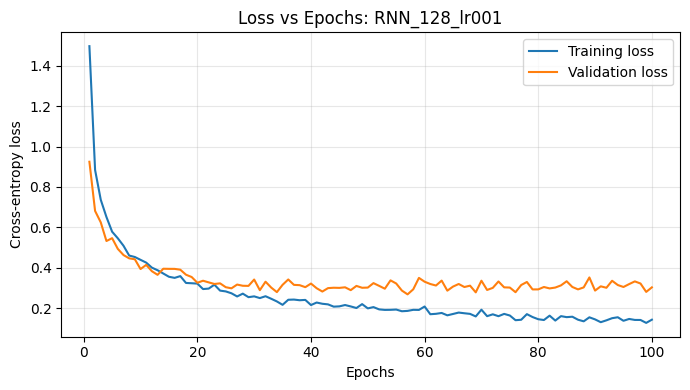

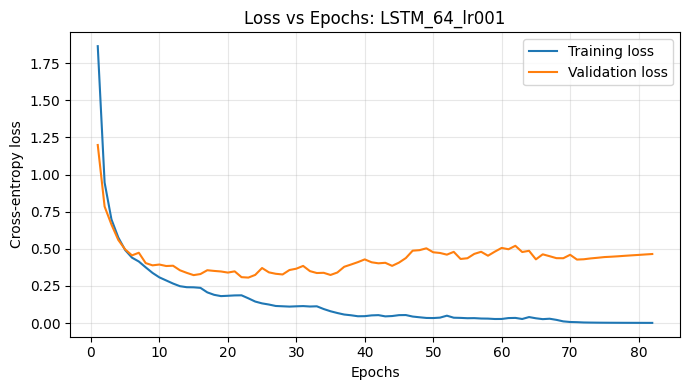

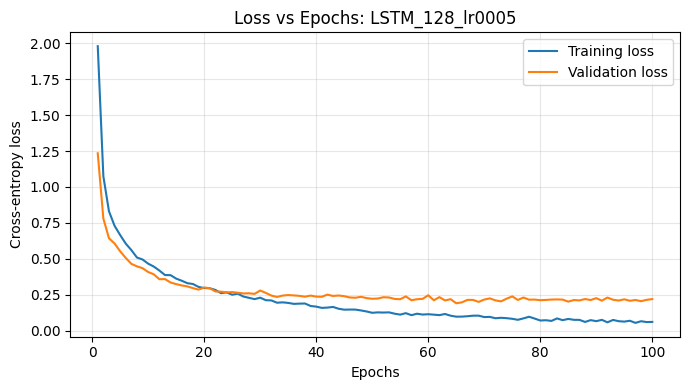

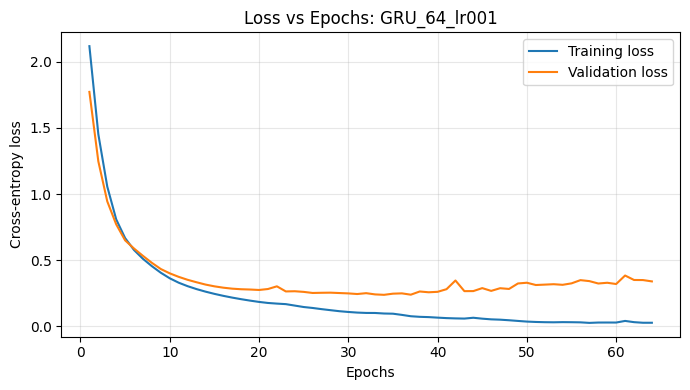

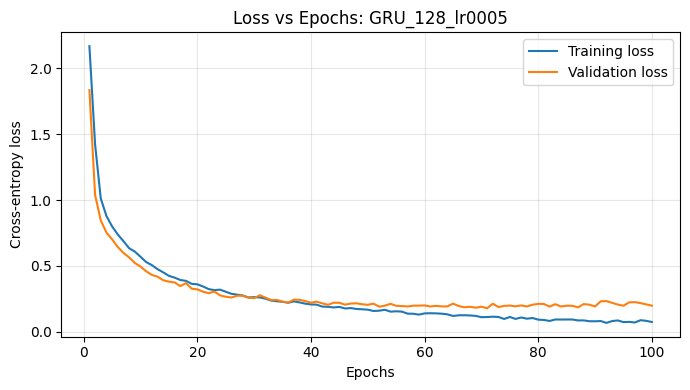

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.flatten()

for ax, config in zip(axes, CONFIGS):
    h = histories[config["name"]]

    train_error = np.array(h["loss"])
    val_error = np.array(h["val_loss"])

    epochs = np.arange(1, len(train_error) + 1)

    ax.plot(epochs, train_error, marker="o",
            markersize=3, label="Training error")
    ax.plot(epochs, val_error, marker="s",
            markersize=3, label="Validation error")

    ax.set_title(config["name"])
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Cross-entropy loss")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("Training and Validation Loss vs Epochs")
plt.tight_layout()
plt.savefig("results/all_training_error_plots.png",
            dpi=200, bbox_inches="tight")
plt.show()

# Save an individual error plot for every configuration
for config in CONFIGS:
    h = histories[config["name"]]
    epochs = np.arange(1, len(h["accuracy"]) + 1)

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, np.array(h["loss"]), label="Training loss")
    plt.plot(epochs, np.array(h["val_loss"]), label="Validation loss")

    plt.title(f"Loss vs Epochs: {config['name']}")
    plt.xlabel("Epochs")
    plt.ylabel("Cross-entropy loss")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        f"results/error_{config['name']}.png",
        dpi=200, bbox_inches="tight"
    )
    plt.show()
    plt.close()

In [9]:
display_df = results_df[
    [
        "Configuration",
        "Architecture",
        "Units",
        "Dropout",
        "Learning Rate",
        "Epochs Trained",
        "Converged",
        "Stopping Reason",
        "Training Accuracy",
        "Validation Accuracy",
        "Test Accuracy"
    ]
].copy()

for col in [
    "Training Accuracy",
    "Validation Accuracy",
    "Test Accuracy"
]:
    display_df[col] = (100 * display_df[col]).round(2)

print("Accuracy comparison (percent). A run is converged only if the absolute change "
      "between consecutive average training losses is below 1e-4.")
display(display_df)

display_df.to_csv(
    "results/accuracy_summary.csv",
    index=False
)

Accuracy comparison (percent):


,Configuration,Architecture,Units,Dropout,Learning Rate,Epochs Trained,Converged,Training Accuracy,Validation Accuracy,Test Accuracy
0,RNN_64_lr001,RNN,64,0.0,0.0010,100,False,93.19,88.54,88.41
1,RNN_128_lr001,RNN,128,0.2,0.0010,100,False,96.82,92.58,91.34
2,LSTM_64_lr001,LSTM,64,0.0,0.0010,82,True,95.33,90.69,90.10
3,LSTM_128_lr0005,LSTM,128,0.2,0.0005,100,False,99.07,93.95,93.10
4,GRU_64_lr001,GRU,64,0.0,0.0010,64,True,97.38,93.49,92.32
5,GRU_128_lr0005,GRU,128,0.2,0.0005,100,False,98.49,94.86,93.95


In [10]:
best_row = results_df.loc[
    results_df["Validation Accuracy"].idxmax()
]

best_name = best_row["Configuration"]
best_model = models[best_name]

print("Best configuration:", best_name)
print("Architecture:", best_row["Architecture"])
print("Hidden units:", best_row["Units"])
print("Dropout:", best_row["Dropout"])
print("Learning rate:", best_row["Learning Rate"])
print(f"Training accuracy: {100*best_row['Training Accuracy']:.2f}%")
print(f"Validation accuracy: {100*best_row['Validation Accuracy']:.2f}%")
print(f"Test accuracy: {100*best_row['Test Accuracy']:.2f}%")

Best configuration: GRU_128_lr0005
Architecture: GRU
Hidden units: 128
Dropout: 0.2
Learning rate: 0.0005
Training accuracy: 98.49%
Validation accuracy: 94.86%
Test accuracy: 93.95%


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Best model: GRU_128_lr0005
Final test accuracy: 93.95%

Classification report:
              precision    recall  f1-score   support

           0     0.9793    0.9281    0.9530       153
           1     0.9730    0.9412    0.9568       153
           2     0.9474    0.9351    0.9412       154
           3     0.9130    0.9545    0.9333       154
           4     0.9671    0.9545    0.9608       154
           5     0.9383    0.9870    0.9620       154
           6     0.9262    0.8961    0.9109       154
           7     0.8889    0.9412    0.9143       153
           8     0.9221    0.9221    0.9221       154
           9     0.9470    0.9346    0.9408       153

    accuracy                         0.9395      1536
   macro avg     0.9402    0.9394    0.9395      1536
weighted avg     0.9402    0.9395    0.9395      1536



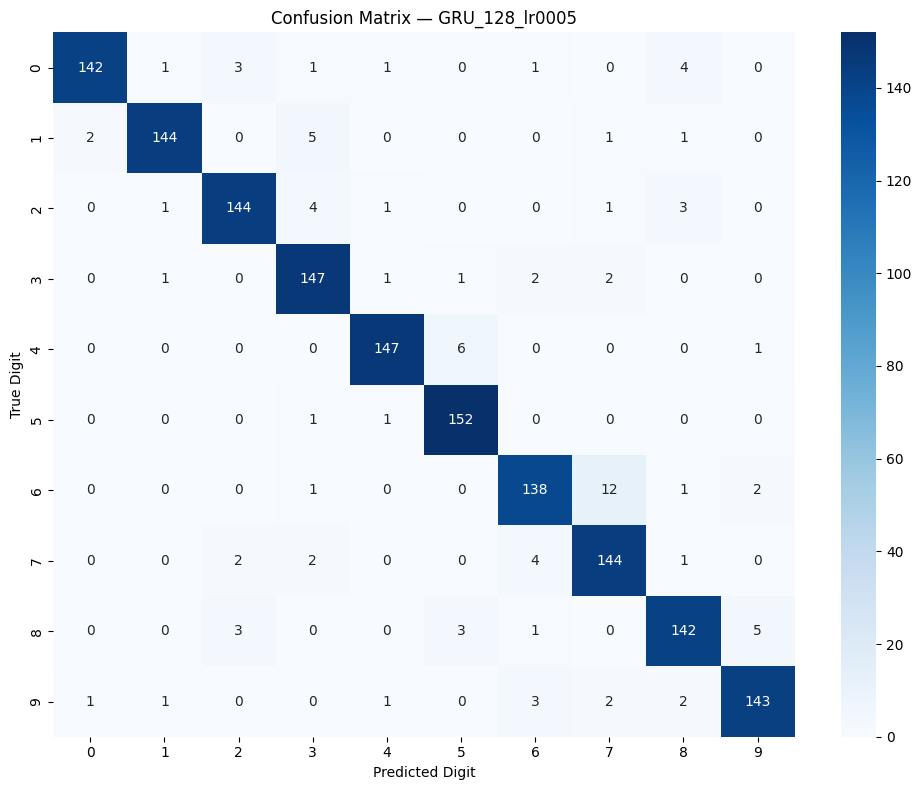

In [11]:
y_prob = best_model.predict(
    X_test, batch_size=BATCH_SIZE, verbose=1
)
y_pred = np.argmax(y_prob, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))

print(f"Best model: {best_name}")
print(f"Final test accuracy: {100*test_accuracy:.2f}%")
print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(10),
        digits=4,
        zero_division=0
    )
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=np.arange(10),
    yticklabels=np.arange(10)
)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted Digit")
plt.ylabel("True Digit")
plt.tight_layout()
plt.savefig("results/best_confusion_matrix.png",
            dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame(
    cm,
    index=[f"True {i}" for i in range(10)],
    columns=[f"Predicted {i}" for i in range(10)]
).to_csv("results/confusion_matrix.csv")

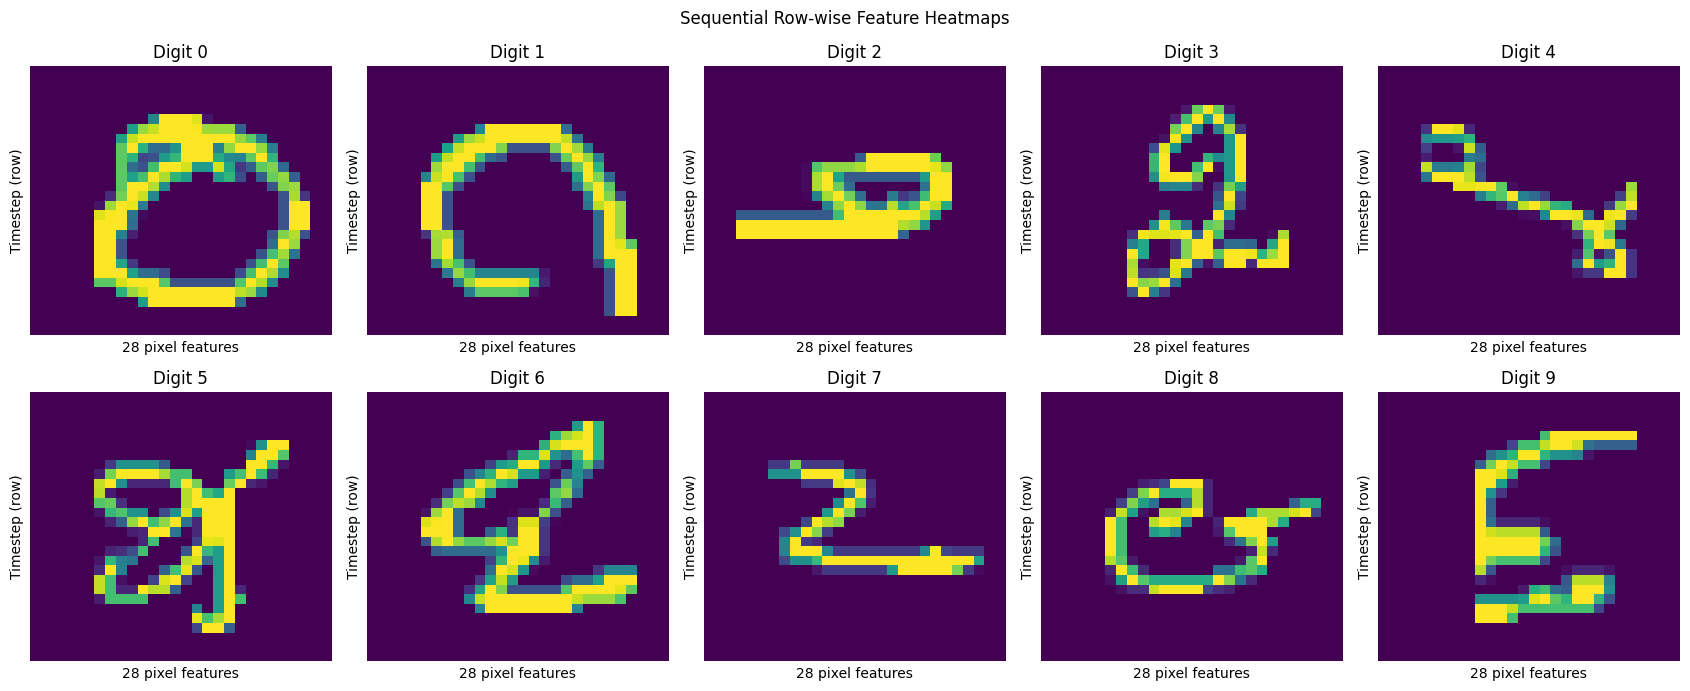

In [12]:
# Choose one test image from each digit class
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
axes = axes.flatten()

for digit in range(10):
    idx = np.where(y_test == digit)[0][0]

    # Each row is one timestep; each column is one pixel feature
    sequence = X_test[idx]

    sns.heatmap(
        sequence,
        ax=axes[digit],
        cmap="viridis",
        cbar=False,
        xticklabels=False,
        yticklabels=False
    )

    axes[digit].set_title(f"Digit {digit}")
    axes[digit].set_xlabel("28 pixel features")
    axes[digit].set_ylabel("Timestep (row)")

plt.suptitle("Sequential Row-wise Feature Heatmaps")
plt.tight_layout()
plt.savefig("results/sequential_feature_heatmaps.png",
            dpi=200, bbox_inches="tight")
plt.show()

  Architecture  Best_Validation_Accuracy  Best_Test_Accuracy
0          GRU                  0.948568            0.939453
1         LSTM                  0.939453            0.930990
2          RNN                  0.925781            0.913411


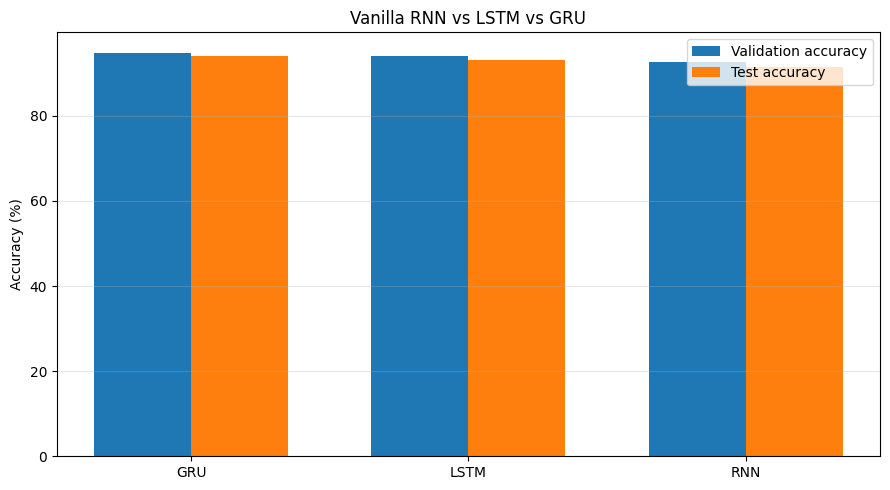

In [13]:
architecture_summary = (
    results_df.groupby("Architecture", as_index=False)
    .agg(
        Best_Validation_Accuracy=("Validation Accuracy", "max"),
        Best_Test_Accuracy=("Test Accuracy", "max")
    )
)

print(architecture_summary)

x = np.arange(len(architecture_summary))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(
    x - width/2,
    architecture_summary["Best_Validation_Accuracy"] * 100,
    width,
    label="Validation accuracy"
)
plt.bar(
    x + width/2,
    architecture_summary["Best_Test_Accuracy"] * 100,
    width,
    label="Test accuracy"
)

plt.xticks(x, architecture_summary["Architecture"])
plt.ylabel("Accuracy (%)")
plt.title("Vanilla RNN vs LSTM vs GRU")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("results/architecture_comparison.png",
            dpi=200, bbox_inches="tight")
plt.show()

In [14]:
import shutil

best_model.save("results/best_task1_model.keras")
results_df.to_csv("results/all_task1_experiment_results.csv", index=False)
shutil.make_archive("Task1_Results", "zip", "results")
print("Saved Task 1 tables, plots, confusion matrix and model to Task1_Results.zip")

Saved Task 1 tables, plots, confusion matrix and model to Task1_Results.zip


## Task 2 — Spoken Arabic digit classification

# Assignment 4 — Task 2: Spoken Digit Sequential Classification

**Dataset:** UCI Spoken Arabic Digit (pre-computed MFCC sequences)  
**Models:** Vanilla RNN, LSTM, and GRU  
**Input:** variable-length sequence of 13 MFCC features per frame; labels 0–9.

This notebook is designed to run in Google Colab or another Python environment with internet access. It downloads the official UCI train/test text files, parses blank-line-separated utterances, uses a validation split from the official training set, and keeps the official test set held out.

> **Important:** the current authoring runtime could not access UCI to download the data, so I have not fabricated accuracy values or training plots. The experiment cells below are fully implemented; run the notebook in Colab to generate genuine results. If you upload `Train_Arabic_Digit.txt` and `Test_Arabic_Digit.txt` here, I can execute the experiments and return a notebook with the actual outputs saved.

## 1. Imports and reproducibility

The code uses PyTorch for the recurrent models and scikit-learn for evaluation metrics.

In [15]:
import os
import random
import urllib.request
from pathlib import Path
import copy
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Random seed:", SEED)

PyTorch: 2.11.0+cpu
Device: cpu
Random seed: 42


## 2. Download and parse the UCI files



In [16]:
DATA_DIR = Path("spoken_arabic_digit_data")
DATA_DIR.mkdir(exist_ok=True)

URLS = {
    "train": "https://archive.ics.uci.edu/ml/machine-learning-databases/00195/Train_Arabic_Digit.txt",
    "test":  "https://archive.ics.uci.edu/ml/machine-learning-databases/00195/Test_Arabic_Digit.txt",
}
FILES = {
    "train": DATA_DIR / "Train_Arabic_Digit.txt",
    "test": DATA_DIR / "Test_Arabic_Digit.txt",
}

def download_if_missing(url, destination):
    if destination.exists() and destination.stat().st_size > 0:
        print(f"Using existing file: {destination}")
        return
    print(f"Downloading {url}")
    try:
        urllib.request.urlretrieve(url, destination)
    except Exception as exc:
        if destination.exists():
            destination.unlink()
        raise RuntimeError(
            f"Could not download the UCI file. Download it manually from the UCI Spoken Arabic Digit page "
            f"and place it at: {destination.resolve()}\nOriginal error: {exc}"
        )

for split in ("train", "test"):
    download_if_missing(URLS[split], FILES[split])

print("Train file size (MB):", round(FILES["train"].stat().st_size / 1e6, 2))
print("Test file size (MB):", round(FILES["test"].stat().st_size / 1e6, 2))

Train file size (MB): 28.34
Test file size (MB): 9.37


In [17]:
def parse_utterance_file(path, utterances_per_digit):
    # Blocks are separated by blank lines; each nonblank line is 13 MFCC values.
    text = Path(path).read_text(encoding="utf-8", errors="ignore")
    blocks = []
    current = []

    for line in text.splitlines():
        line = line.strip()
        if not line:
            if current:
                blocks.append(np.asarray(current, dtype=np.float32))
                current = []
            continue
        values = np.fromstring(line, sep=" ", dtype=np.float32)
        if values.size:
            if values.size != 13:
                raise ValueError(f"Expected 13 MFCCs per frame, got {values.size} in {path}")
            current.append(values)

    if current:
        blocks.append(np.asarray(current, dtype=np.float32))

    expected = 10 * utterances_per_digit
    if len(blocks) != expected:
        raise ValueError(
            f"Expected {expected} utterance blocks in {path}, but parsed {len(blocks)}. "
            "Check that the original UCI text file was downloaded without modification."
        )

    labels = np.repeat(np.arange(10, dtype=np.int64), utterances_per_digit)
    return blocks, labels

X_all, y_all = parse_utterance_file(FILES["train"], utterances_per_digit=660)
X_test, y_test = parse_utterance_file(FILES["test"], utterances_per_digit=220)

print("Training utterances:", len(X_all))
print("Test utterances:", len(X_test))
print("Number of classes:", len(np.unique(y_all)))
print("Feature dimension:", X_all[0].shape[1])
print("Training sequence lengths:", min(map(len, X_all)), "to", max(map(len, X_all)))
print("Test sequence lengths:", min(map(len, X_test)), "to", max(map(len, X_test)))

Training utterances: 6600
Test utterances: 2200
Number of classes: 10
Feature dimension: 13
Training sequence lengths: 4 to 93
Test sequence lengths: 7 to 83


## 3. Training/validation split and feature normalization

The official test set is kept untouched for final evaluation. A stratified 15% validation split is sampled from the official training set. MFCC features are standardized using the mean and standard deviation calculated from **training frames only**; the same transform is applied to validation and test frames.

In [18]:
indices = np.arange(len(X_all))
train_idx, val_idx = train_test_split(
    indices, test_size=0.15, random_state=SEED, stratify=y_all
)

X_train_raw = [X_all[i] for i in train_idx]
y_train = y_all[train_idx]
X_val_raw = [X_all[i] for i in val_idx]
y_val = y_all[val_idx]

# Estimate feature-wise mean/std using only training frames.
train_frames = np.concatenate(X_train_raw, axis=0)
feature_mean = train_frames.mean(axis=0, keepdims=True)
feature_std = train_frames.std(axis=0, keepdims=True)
feature_std[feature_std < 1e-6] = 1.0

def standardize_sequences(sequences):
    return [((seq - feature_mean) / feature_std).astype(np.float32) for seq in sequences]

X_train = standardize_sequences(X_train_raw)
X_val = standardize_sequences(X_val_raw)
X_test_scaled = standardize_sequences(X_test)

print(f"Training set:   {len(X_train):,} utterances")
print(f"Validation set: {len(X_val):,} utterances")
print(f"Test set:       {len(X_test_scaled):,} utterances")
print("Training label counts:", dict(zip(*np.unique(y_train, return_counts=True))))

Training set:   5,610 utterances
Validation set: 990 utterances
Test set:       2,200 utterances
Training label counts: {np.int64(0): np.int64(561), np.int64(1): np.int64(561), np.int64(2): np.int64(561), np.int64(3): np.int64(561), np.int64(4): np.int64(561), np.int64(5): np.int64(561), np.int64(6): np.int64(561), np.int64(7): np.int64(561), np.int64(8): np.int64(561), np.int64(9): np.int64(561)}


## 4. Visualize MFCC sequences

The heatmaps show the 13 MFCC coefficients over time for one representative utterance from each digit class. These are input-feature visualizations, not model hidden-state visualizations.

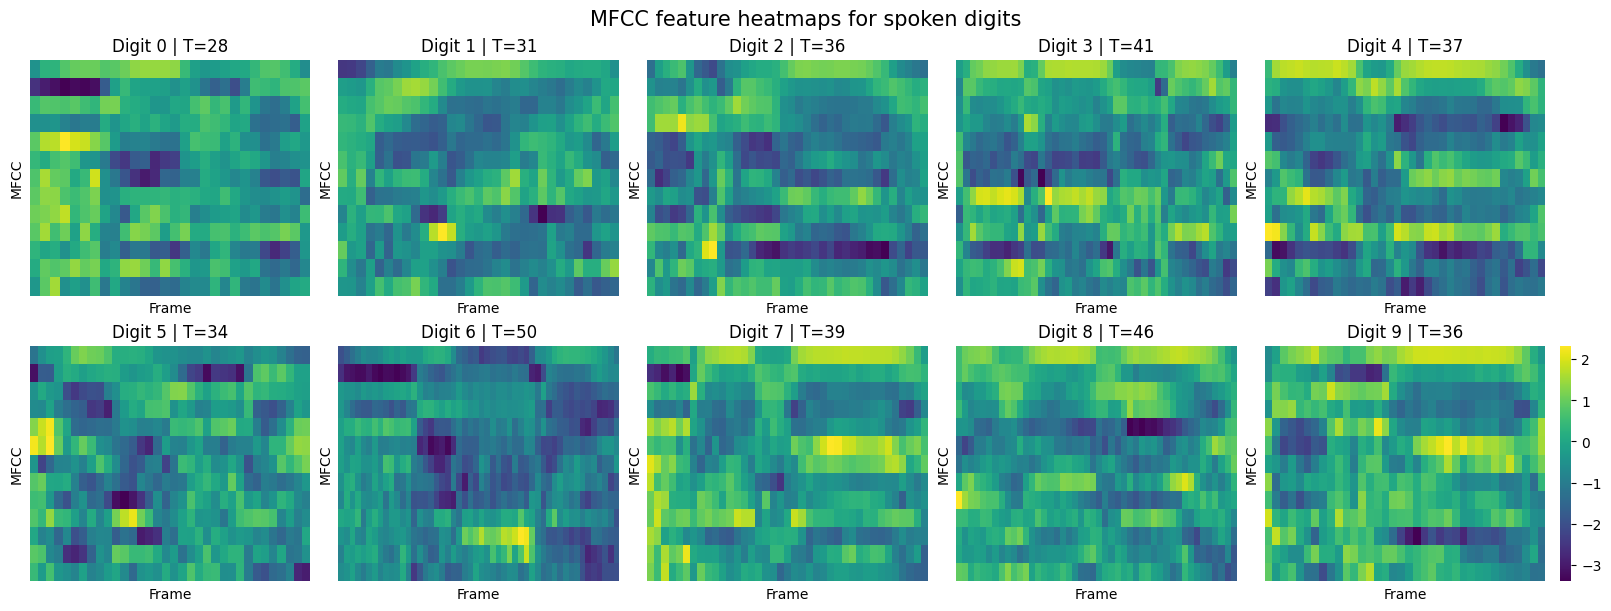

In [19]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6), constrained_layout=True)
axes = axes.ravel()

for digit in range(10):
    idx = next(i for i, label in enumerate(y_test) if label == digit)
    seq = X_test_scaled[idx]
    sns.heatmap(seq.T, ax=axes[digit], cmap="viridis", cbar=(digit == 9),
                xticklabels=False, yticklabels=False)
    axes[digit].set_title(f"Digit {digit} | T={len(seq)}")
    axes[digit].set_xlabel("Frame")
    axes[digit].set_ylabel("MFCC")

fig.suptitle("MFCC feature heatmaps for spoken digits", fontsize=15)
plt.show()

## 5. Dataset loader and variable-length batching

Sequences in a batch are padded to the longest sequence in that batch. The original sequence lengths are passed to `pack_padded_sequence`, so the recurrent layer ignores padded frames.

In [20]:
class MFCCDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = sequences
        self.labels = np.asarray(labels, dtype=np.int64)

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return torch.tensor(self.sequences[idx], dtype=torch.float32), int(self.labels[idx])

def collate_sequences(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)
    padded = pad_sequence(sequences, batch_first=True, padding_value=0.0)
    labels = torch.tensor(labels, dtype=torch.long)
    return padded, lengths, labels

BATCH_SIZE = 64
train_loader = DataLoader(MFCCDataset(X_train, y_train), batch_size=BATCH_SIZE,
                          shuffle=True, collate_fn=collate_sequences)
val_loader = DataLoader(MFCCDataset(X_val, y_val), batch_size=BATCH_SIZE,
                        shuffle=False, collate_fn=collate_sequences)
test_loader = DataLoader(MFCCDataset(X_test_scaled, y_test), batch_size=BATCH_SIZE,
                         shuffle=False, collate_fn=collate_sequences)

print("Batches — train:", len(train_loader), "| validation:", len(val_loader), "| test:", len(test_loader))

Batches — train: 88 | validation: 16 | test: 35


## 6. Model definition

Each architecture uses one recurrent layer followed by a fully connected 10-class output layer. The hyperparameter search varies recurrent type, hidden size, number of recurrent layers, and dropout. For multilayer recurrent models, dropout is applied between recurrent layers when supported by PyTorch.

In [21]:
class RecurrentClassifier(nn.Module):
    def __init__(self, cell_type="RNN", input_size=13, hidden_size=64,
                 num_layers=1, dropout=0.0, num_classes=10):
        super().__init__()
        self.cell_type = cell_type.upper()
        recurrent_dropout = dropout if num_layers > 1 else 0.0

        if self.cell_type == "RNN":
            self.rnn = nn.RNN(input_size, hidden_size, num_layers=num_layers,
                              batch_first=True, nonlinearity="tanh",
                              dropout=recurrent_dropout)
        elif self.cell_type == "LSTM":
            self.rnn = nn.LSTM(input_size, hidden_size, num_layers=num_layers,
                               batch_first=True, dropout=recurrent_dropout)
        elif self.cell_type == "GRU":
            self.rnn = nn.GRU(input_size, hidden_size, num_layers=num_layers,
                              batch_first=True, dropout=recurrent_dropout)
        else:
            raise ValueError("cell_type must be RNN, LSTM, or GRU")

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, x, lengths):
        packed = pack_padded_sequence(
            x, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, hidden = self.rnn(packed)

        # LSTM returns (hidden_state, cell_state); other cells return hidden_state.
        if self.cell_type == "LSTM":
            hidden = hidden[0]
        last_hidden = hidden[-1]
        return self.classifier(self.dropout(last_hidden))

## 7. Training and convergence rule

The stopping criterion follows the assignment: stop when the absolute difference between average training losses from consecutive epochs is below `1e-4`. A maximum epoch count is retained only as a safety cap. Validation loss is monitored to save the best checkpoint, and validation accuracy is used to select the best hyperparameter configuration.

In [22]:
MAX_EPOCHS = 100  # safety cap only
CONVERGENCE_TOL = 1e-4


def run_epoch(model, loader, criterion, optimizer=None, return_grad_norm=False):
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total_count = 0.0, 0, 0
    grad_norms = []

    for padded, lengths, labels in loader:
        padded = padded.to(DEVICE)
        labels = labels.to(DEVICE)
        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(padded, lengths)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                total_norm_sq = 0.0
                for p in model.parameters():
                    if p.grad is not None:
                        total_norm_sq += p.grad.detach().norm(2).item() ** 2
                grad_norms.append(total_norm_sq ** 0.5)  # before clipping
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()

        n = labels.size(0)
        total_loss += loss.item() * n
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_count += n

    values = (total_loss / total_count, total_correct / total_count)
    if return_grad_norm:
        return values + (float(np.mean(grad_norms)) if grad_norms else np.nan,)
    return values


def fit_model(config, train_loader, val_loader):
    model = RecurrentClassifier(
        cell_type=config["cell"], hidden_size=config["hidden"],
        num_layers=config["layers"], dropout=config["dropout"]
    ).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"])

    history = {"train_loss": [], "train_accuracy": [], "val_loss": [],
               "val_accuracy": [], "gradient_norm": []}
    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    converged = False
    stop_reason = "maximum epoch safety cap reached"
    start = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, train_acc, grad_norm = run_epoch(
            model, train_loader, criterion, optimizer, return_grad_norm=True
        )
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)
        history["gradient_norm"].append(grad_norm)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

        change = abs(history["train_loss"][-1] - history["train_loss"][-2]) if epoch > 1 else None
        print(f"Epoch {epoch:03d} | train loss {train_loss:.5f} | train acc {train_acc:.4f} | "
              f"val loss {val_loss:.5f} | val acc {val_acc:.4f}"
              + (f" | Δloss {change:.6g}" if change is not None else ""))

        if change is not None and change < CONVERGENCE_TOL:
            converged = True
            stop_reason = f"converged: |Δ training loss|={change:.6g} < {CONVERGENCE_TOL}"
            break

    model.load_state_dict(best_state)
    history["seconds"] = time.time() - start
    history["epochs"] = len(history["train_loss"])
    history["converged"] = converged
    history["stop_reason"] = stop_reason
    print(stop_reason)
    return model, history

## 8. Hyperparameter experiments

The configurations below compare all three recurrent cell types and vary hidden size, recurrent depth, and dropout.

In [23]:
CONFIGS = [
    {"name": "RNN_64_1layer",  "cell": "RNN",  "hidden": 64,  "layers": 1, "dropout": 0.0, "lr": 1e-3},
    {"name": "RNN_128_1layer", "cell": "RNN",  "hidden": 128, "layers": 1, "dropout": 0.2, "lr": 1e-3},
    {"name": "RNN_64_2layer",  "cell": "RNN",  "hidden": 64,  "layers": 2, "dropout": 0.2, "lr": 1e-3},
    {"name": "LSTM_64_1layer", "cell": "LSTM", "hidden": 64,  "layers": 1, "dropout": 0.0, "lr": 1e-3},
    {"name": "LSTM_128_1layer","cell": "LSTM", "hidden": 128, "layers": 1, "dropout": 0.2, "lr": 5e-4},
    {"name": "LSTM_64_2layer", "cell": "LSTM", "hidden": 64,  "layers": 2, "dropout": 0.2, "lr": 1e-3},
    {"name": "GRU_64_1layer",  "cell": "GRU",  "hidden": 64,  "layers": 1, "dropout": 0.0, "lr": 1e-3},
    {"name": "GRU_128_1layer", "cell": "GRU",  "hidden": 128, "layers": 1, "dropout": 0.2, "lr": 5e-4},
    {"name": "GRU_64_2layer",  "cell": "GRU",  "hidden": 64,  "layers": 2, "dropout": 0.2, "lr": 1e-3},
]

histories = {}
models = {}
rows = []

for config in CONFIGS:
    print("\n" + "=" * 72)
    print("Training:", config["name"])
    print("=" * 72)
    model, history = fit_model(config, train_loader, val_loader)
    models[config["name"]] = model
    histories[config["name"]] = history

    train_loss, train_acc = run_epoch(model, train_loader, nn.CrossEntropyLoss())
    val_loss, val_acc = run_epoch(model, val_loader, nn.CrossEntropyLoss())
    test_loss, test_acc_each = run_epoch(model, test_loader, nn.CrossEntropyLoss())
    rows.append({
        "Configuration": config["name"],
        "Cell": config["cell"],
        "Hidden units": config["hidden"],
        "Recurrent layers": config["layers"],
        "Dropout": config["dropout"],
        "Learning rate": config["lr"],
        "Epochs": history["epochs"],
        "Converged": history["converged"],
        "Stopping reason": history["stop_reason"],
        "Training accuracy": train_acc,
        "Validation accuracy": val_acc,
        "Test accuracy": test_acc_each,
        "Test loss": test_loss,
        "Best validation loss": min(history["val_loss"]),
        "Training time (s)": history["seconds"],
    })

results_df = pd.DataFrame(rows).sort_values("Validation accuracy", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "Training accuracy": "{:.4f}",
    "Validation accuracy": "{:.4f}",
    "Test accuracy": "{:.4f}",
    "Best validation loss": "{:.5f}",
    "Training time (s)": "{:.1f}",
}))

# Preserve Task 2 results for the final cross-task convergence audit.
task2_results_df = results_df.copy()


Training: RNN_64_1layer
Epoch 001 | train loss 1.82664 | train acc 0.3358 | val loss 1.45402 | val acc 0.4505
Epoch 002 | train loss 1.35565 | train acc 0.4909 | val loss 1.24964 | val acc 0.5273 | Δloss 0.47099
Epoch 003 | train loss 1.19246 | train acc 0.5608 | val loss 1.11729 | val acc 0.5677 | Δloss 0.16319
Epoch 004 | train loss 1.06762 | train acc 0.5998 | val loss 0.99350 | val acc 0.6293 | Δloss 0.124832
Epoch 005 | train loss 0.90817 | train acc 0.6690 | val loss 0.80793 | val acc 0.7101 | Δloss 0.159453
Epoch 006 | train loss 0.77406 | train acc 0.7146 | val loss 0.74858 | val acc 0.7293 | Δloss 0.134111
Epoch 007 | train loss 0.69577 | train acc 0.7446 | val loss 0.62437 | val acc 0.7889 | Δloss 0.0782893
Epoch 008 | train loss 0.61290 | train acc 0.7722 | val loss 0.59313 | val acc 0.7980 | Δloss 0.0828668
Epoch 009 | train loss 0.55441 | train acc 0.8005 | val loss 0.49878 | val acc 0.8263 | Δloss 0.0584925
Epoch 010 | train loss 0.52052 | train acc 0.8153 | val loss 0.5

,Configuration,Cell,Hidden units,Recurrent layers,Dropout,Learning rate,Epochs,Converged,Stopping reason,Training accuracy,Validation accuracy,Test accuracy,Test loss,Best validation loss,Training time (s)
0,LSTM_64_2layer,LSTM,64,2,0.200000,0.001000,36,True,converged: |Δ training loss|=9.22212e-05 < 0.0001,1.0000,0.9980,0.9727,0.165024,0.01544,457.9
1,GRU_64_2layer,GRU,64,2,0.200000,0.001000,40,True,converged: |Δ training loss|=3.9062e-05 < 0.0001,0.9998,0.9960,0.9609,0.191893,0.01601,442.5
2,GRU_128_1layer,GRU,128,1,0.200000,0.000500,36,True,converged: |Δ training loss|=8.81935e-05 < 0.0001,0.9998,0.9939,0.9627,0.168537,0.01954,331.4
3,GRU_64_1layer,GRU,64,1,0.000000,0.001000,30,True,converged: |Δ training loss|=7.56952e-05 < 0.0001,1.0000,0.9929,0.9473,0.228778,0.02291,158.3
4,LSTM_64_1layer,LSTM,64,1,0.000000,0.001000,44,True,converged: |Δ training loss|=8.6553e-05 < 0.0001,0.9984,0.9929,0.9459,0.213659,0.03350,269.1
5,LSTM_128_1layer,LSTM,128,1,0.200000,0.000500,39,True,converged: |Δ training loss|=5.14862e-05 < 0.0001,0.9996,0.9899,0.9564,0.168162,0.04177,461.2
6,RNN_64_2layer,RNN,64,2,0.200000,0.001000,100,False,maximum epoch safety cap reached,0.9902,0.9869,0.9173,0.444428,0.07095,428.2
7,RNN_128_1layer,RNN,128,1,0.200000,0.001000,100,False,maximum epoch safety cap reached,0.9943,0.9848,0.9373,0.305937,0.06680,342.0
8,RNN_64_1layer,RNN,64,1,0.000000,0.001000,100,False,maximum epoch safety cap reached,0.9907,0.9727,0.8964,0.542520,0.11320,210.6


## 9. Training-loss curves for every configuration

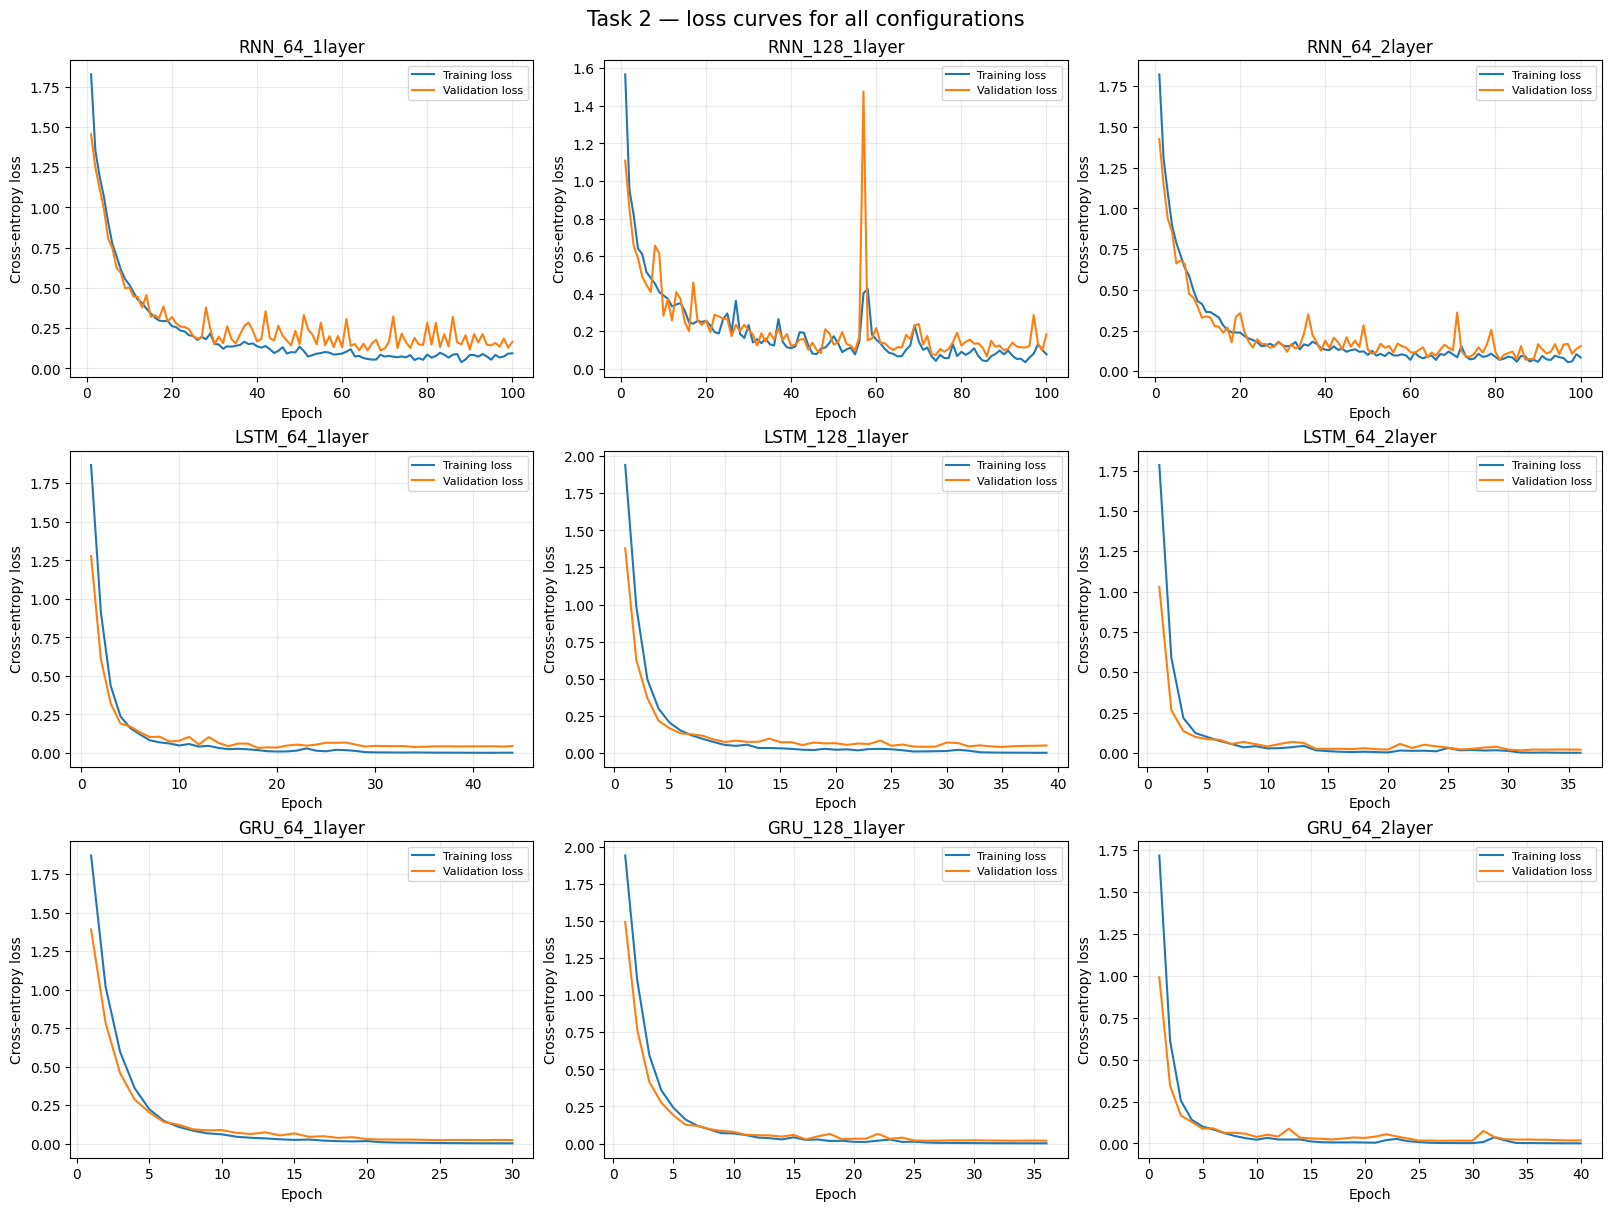

In [24]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12), constrained_layout=True)
for ax, config in zip(axes.ravel(), CONFIGS):
    h = histories[config["name"]]
    epochs = np.arange(1, len(h["train_loss"]) + 1)
    ax.plot(epochs, h["train_loss"], label="Training loss")
    ax.plot(epochs, h["val_loss"], label="Validation loss")
    ax.set_title(config["name"])
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-entropy loss")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
for ax in axes.ravel()[len(CONFIGS):]:
    ax.axis("off")
fig.suptitle("Task 2 — loss curves for all configurations", fontsize=15)
plt.show()

## 10. Select the best model and evaluate the held-out test set

The best configuration is selected by validation accuracy. The official test set is evaluated once after model selection.

In [25]:
best_name = results_df.iloc[0]["Configuration"]
best_model = models[best_name]
best_config = next(c for c in CONFIGS if c["name"] == best_name)

print("Best configuration:", best_name)
print("Selected by validation accuracy:", f'{results_df.iloc[0]["Validation accuracy"]:.4f}')

@torch.no_grad()
def predict_model(model, loader):
    model.eval()
    all_y, all_pred = [], []
    for padded, lengths, labels in loader:
        logits = model(padded.to(DEVICE), lengths)
        all_y.extend(labels.numpy().tolist())
        all_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
    return np.asarray(all_y), np.asarray(all_pred)

y_test_true, y_test_pred = predict_model(best_model, test_loader)
test_acc = accuracy_score(y_test_true, y_test_pred)
print(f"Best model test accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")
print("\nClassification report:")
print(classification_report(y_test_true, y_test_pred, digits=4, zero_division=0))

Best configuration: LSTM_64_2layer
Selected by validation accuracy: 0.9980
Best model test accuracy: 0.9727 (97.27%)

Classification report:
              precision    recall  f1-score   support

           0     0.8852    0.9818    0.9310       220
           1     0.9865    0.9955    0.9910       220
           2     0.9864    0.9909    0.9887       220
           3     0.9583    0.9409    0.9495       220
           4     0.9909    0.9909    0.9909       220
           5     0.9909    0.9909    0.9909       220
           6     1.0000    0.9000    0.9474       220
           7     0.9633    0.9545    0.9589       220
           8     0.9864    0.9864    0.9864       220
           9     0.9910    0.9955    0.9932       220

    accuracy                         0.9727      2200
   macro avg     0.9739    0.9727    0.9728      2200
weighted avg     0.9739    0.9727    0.9728      2200



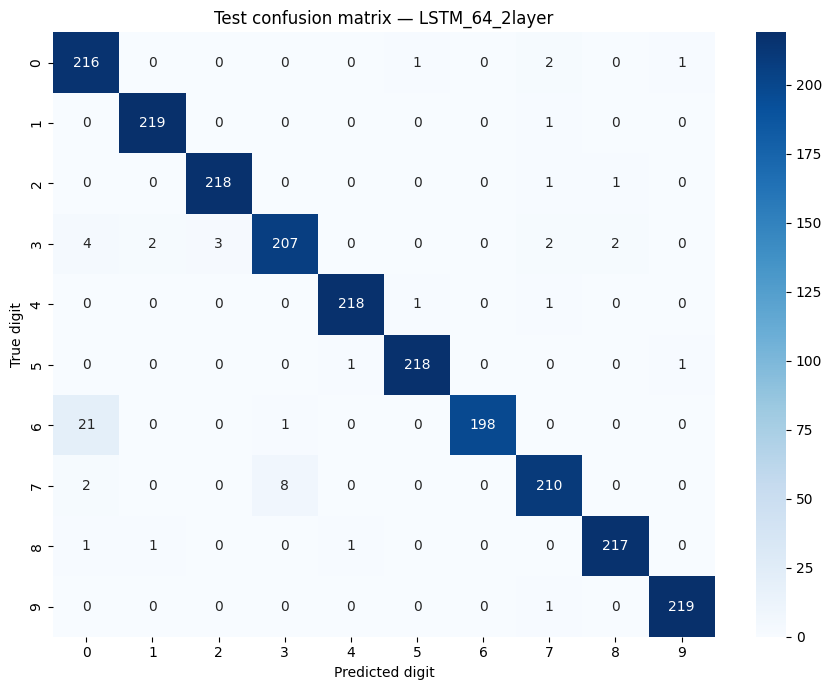

In [26]:
cm = confusion_matrix(y_test_true, y_test_pred, labels=np.arange(10))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=np.arange(10), yticklabels=np.arange(10))
plt.title(f"Test confusion matrix — {best_name}")
plt.xlabel("Predicted digit")
plt.ylabel("True digit")
plt.tight_layout()
plt.show()

## 11. Compare RNN, LSTM, and GRU



,Cell,Best_configuration,Best_validation_accuracy,Mean_training_accuracy
0,GRU,GRU_64_2layer,0.9960,0.9999
1,LSTM,LSTM_64_2layer,0.9980,0.9993
2,RNN,RNN_64_2layer,0.9869,0.9917


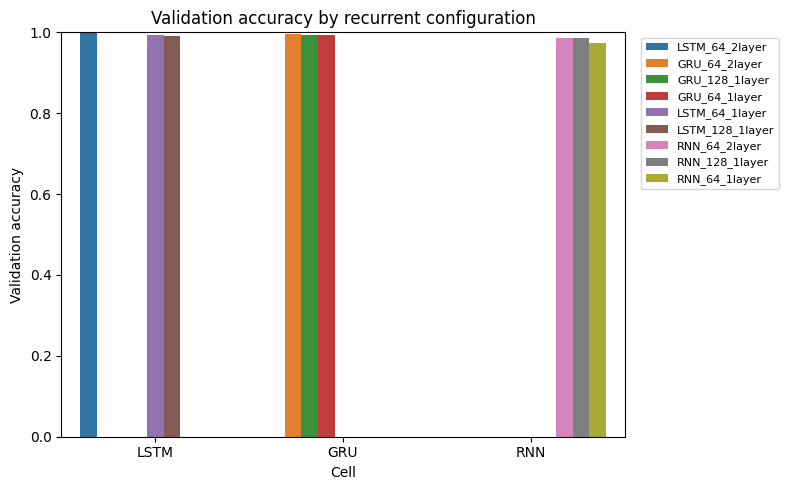

In [27]:
architecture_summary = (
    results_df.groupby("Cell", as_index=False)
    .agg(
        Best_configuration=("Configuration", lambda s: s.iloc[
            results_df.loc[s.index, "Validation accuracy"].to_numpy().argmax()
        ]),
        Best_validation_accuracy=("Validation accuracy", "max"),
        Mean_training_accuracy=("Training accuracy", "mean"),
    )
)
display(architecture_summary.style.format({
    "Best_validation_accuracy": "{:.4f}",
    "Mean_training_accuracy": "{:.4f}",
}))

plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x="Cell", y="Validation accuracy", hue="Configuration")
plt.title("Validation accuracy by recurrent configuration")
plt.ylabel("Validation accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 12. Gradient diagnostics

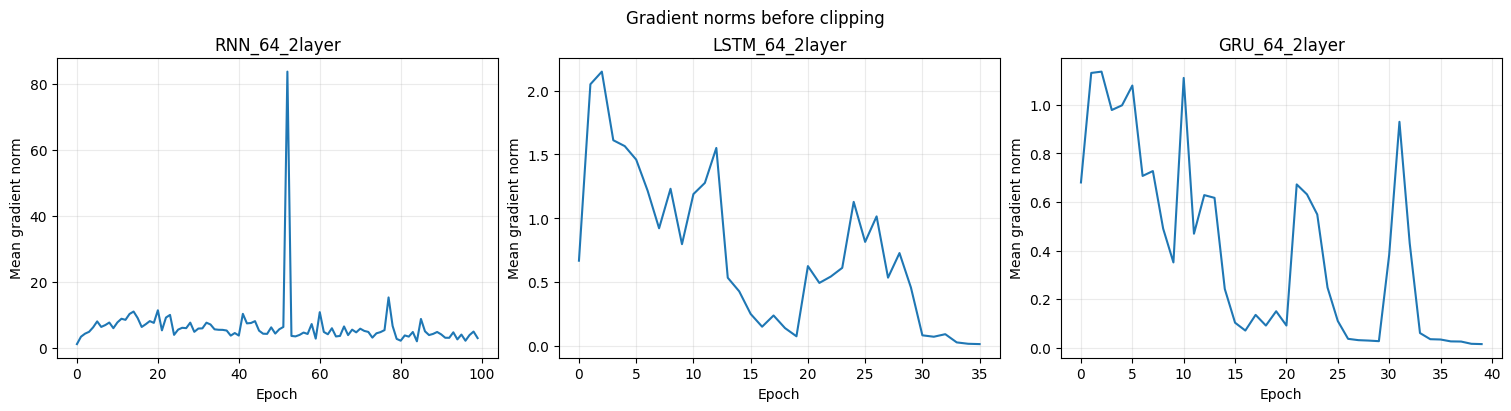

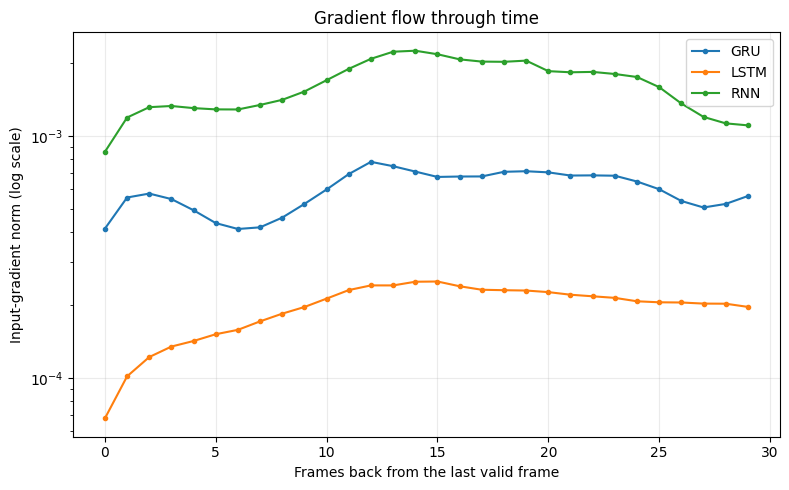

In [28]:
# Gradient norms before clipping, recorded during training.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, cell in zip(axes, ["RNN", "LSTM", "GRU"]):
    row = results_df[results_df["Cell"] == cell].sort_values("Validation accuracy", ascending=False).iloc[0]
    name = row["Configuration"]
    ax.plot(histories[name]["gradient_norm"])
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean gradient norm")
    ax.grid(alpha=0.25)
plt.suptitle("Gradient norms before clipping")
plt.show()

# Input-gradient magnitude by distance from the last valid frame.
best_by_cell = results_df.loc[results_df.groupby("Cell")["Validation accuracy"].idxmax()]
flow_profiles = {}
criterion = nn.CrossEntropyLoss()
for _, row in best_by_cell.iterrows():
    model = models[row["Configuration"]]
    model.eval()
    totals = np.zeros(30, dtype=np.float64)
    counts = np.zeros(30, dtype=np.int64)
    for padded, lengths, labels in test_loader:
        keep = lengths >= 30
        if not keep.any():
            continue
        x = padded[keep].to(DEVICE).detach().requires_grad_(True)
        lens = lengths[keep]
        yb = labels[keep].to(DEVICE)
        logits = model(x, lens)
        loss = criterion(logits, yb)
        grad = torch.autograd.grad(loss, x)[0]
        for b, length in enumerate(lens.tolist()):
            for d in range(min(30, length)):
                totals[d] += grad[b, length - 1 - d].norm().item()
                counts[d] += 1
    flow_profiles[row["Cell"]] = totals / np.maximum(counts, 1)

distances = np.arange(30)
plt.figure(figsize=(8, 5))
for cell, profile in flow_profiles.items():
    plt.plot(distances, profile, marker=".", label=cell)
plt.yscale("log")
plt.xlabel("Frames back from the last valid frame")
plt.ylabel("Input-gradient norm (log scale)")
plt.title("Gradient flow through time")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## 14. Results


In [29]:
OUTPUT_DIR = Path("task2_results")
OUTPUT_DIR.mkdir(exist_ok=True)

results_df.to_csv(OUTPUT_DIR / "task2_hyperparameter_results.csv", index=False)
torch.save({
    "model_state_dict": best_model.state_dict(),
    "configuration": best_config,
    "feature_mean": feature_mean,
    "feature_std": feature_std,
    "test_accuracy": test_acc,
}, OUTPUT_DIR / "best_task2_model.pt")

print("Saved:")
print("-", OUTPUT_DIR / "task2_hyperparameter_results.csv")
print("-", OUTPUT_DIR / "best_task2_model.pt")

Saved:
- task2_results/task2_hyperparameter_results.csv
- task2_results/best_task2_model.pt


## Convergence audit and interpretation

The stopping condition for both tasks is the absolute difference between consecutive **average training losses** being less than `1e-4`. The epoch limit is only a safety cap; reaching it does **not** count as convergence. The `Converged` and `Stopping Reason` fields must be reported for every configuration.

For Task 1, the current executed results show four configurations reached the 100-epoch safety cap without satisfying the threshold. Their results are useful for comparison, but they must not be described as converged. The best validation-accuracy model is `GRU_128_lr0005` (94.86% validation, 93.95% test); it also reached the cap, so the best-accuracy result is provisional with respect to the required convergence rule.

For Task 2, six of nine configurations met the threshold; the three RNN configurations reached the safety cap. The selected model is `LSTM_64_2layer` (99.80% validation, 97.27% test). The model is selected by validation accuracy, not by test accuracy.

The gradient-norm plots are diagnostic evidence, not a controlled proof that architecture alone caused the differences. RNNs can be more vulnerable to vanishing/exploding gradients over long sequences; LSTM and GRU gates provide paths for retaining information and often make optimization more stable. Actual outcomes also depend on hidden size, number of layers, dropout, learning rate, sequence length, and random variation.

In [ ]:
# Convergence audit: run after both tasks have been trained.
# A run is converged only when the absolute difference between consecutive
# average training losses is below 1e-4. Reaching the safety cap is not convergence.
audit_rows = []

if "task1_results_df" in globals():
    t1 = task1_results_df.copy()
    t1.insert(0, "Task", "Task 1 — Kannada")
    audit_rows.append(t1[["Task", "Configuration", "Epochs Trained", "Converged", "Stopping Reason"]])

if "task2_results_df" in globals():
    t2 = task2_results_df.copy()
    t2.insert(0, "Task", "Task 2 — Spoken Arabic")
    t2 = t2.rename(columns={"Epochs": "Epochs Trained"})
    audit_rows.append(t2[["Task", "Configuration", "Epochs Trained", "Converged", "Stopping reason"]]
                      .rename(columns={"Stopping reason": "Stopping Reason"}))

if audit_rows:
    convergence_audit = pd.concat(audit_rows, ignore_index=True)
    display(convergence_audit)
    convergence_audit.to_csv("convergence_audit.csv", index=False)
else:
    print("Run all training cells above before creating the convergence audit.")